# The first models: a step-by-step walkthrough of `src/ml/`

This notebook walks through the first round of machine-learning models for the CCD optimization. It covers what each model does, how
it is trained and tested, and what the results say. The document version, with the theory in plain and precise form, is
`docs/overleaf_ml_models/ml_models.tex`.

**There are no labeled packets with varied settings yet.** Everything here runs on a *synthetic CCD world*
(`src/ml/synthetic.py`) that produces packets in exactly the format of the real `dataset.csv`, so the same code will run on the real
scan. The synthetic numbers compare methods; they say nothing about the real CCD.

| Step | What |
|---|---|
| 1 | The synthetic world: settings, labels, hand-made features, curves, the hidden state and the intermittent pickup |
| 2 | Inputs and targets: what a model is given and what it predicts |
| 3 | The five model types, fitted on one scan and tested on another |
| 4 | Error bars: are the uncertainties honest? |
| 5 | What the Gaussian process uses |
| 6 | The benchmark: number of packets, features vs curves, a new module |
| 7 | Bayesian optimization: choosing the next settings |
| 8 | Real data: loading `dataset.csv` and the curves |

Run with the project environment (`.venv`, from `requirements-ml.txt`); the whole notebook takes a few minutes.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from ml import synthetic, data, models, evaluate, optimize

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
RESULTS = PROJECT / "docs" / "ml_results"            # written by: python -m ml.benchmark
FIGS = PROJECT / "docs" / "overleaf_ml_models" / "figures"
print("torch device for the CNN:", models.CurveCNN().device)

torch device for the CNN: mps


## 1. The synthetic world

`synthetic.make_dataset(n_packets)` simulates a scan:

* **10 operating parameters** with the real names and nominal values (groups of pins move together: e.g. `H_low` = all horizontal low
  rails), drawn at random inside their ranges, but never breaking the relation VDRAIN − VDD ≤ −2.5 V (a stand-in for the real
  relations, which are encoded in `ccd_limits.py` since 2026-10-14 from the group's `docs/voltage_rules.txt`, e.g. VDD > VDRAIN);
* **4 amplifiers per board**, the third about 4× noisier (like CCD_A);
* **labels** as WADERs would give them: read noise σe, dark charge λ per pixel, gain, with the label noise of the 16-row image;
* **17 hand-made features** (real names) and **7 curves**, at θ and at the reference, with the measured repeat scatter;
* a **hidden state** that drifts slowly from packet to packet (think temperature): it changes λ by ±35 % and moves a few trace
  features, but it is not in θ;
* **intermittent pickup**, on in 40 % of the packets: a noise floor that does not average down with more skips. It is visible only in
  the noise curves (Allan deviation, CDS spectrum), **not** in any of the hand-made features. This tests whether a model can find an
  effect we did not build a feature for.

In [2]:
train_df, train_curves = synthetic.make_dataset(240, seed=1)     # the "scan": 240 packets x 4 amplifiers
test_df, test_curves = synthetic.make_dataset(200, seed=99)      # an independent scan of the same CCDs
print(train_df.shape, "rows x columns;", train_df["packet_id"].nunique(), "packets")
print("column groups:", pd.Series([c.split(".")[0] for c in train_df.columns]).value_counts().to_dict())
train_df.filter(regex="^(packet_id|channel|theta\\.VDD|theta\\.H_low|label|truth\\.(state|pickup))").head(8).round(4)

(960, 86) rows x columns; 240 packets
column groups: {'trace': 17, 'ref': 17, 'diff': 17, 'theta': 10, 'delta': 10, 'truth': 7, 'label': 4, 'packet_id': 1, 'board': 1, 'channel': 1, 'amplifier': 1}


,packet_id,channel,theta.VDD,theta.H_low,label.sigma_e,label.lambda_e_per_bin,label.gain_adu_per_e,label.ok,truth.state,truth.pickup
0,syn_00000,0,-18.9527,6.0989,0.3042,0.0922,1.3329,True,0.3637,0.0
1,syn_00000,1,-18.9527,6.0989,0.3056,0.0889,1.2829,True,0.3637,0.0
2,syn_00000,2,-18.9527,6.0989,1.2355,0.0939,2.6424,True,0.3637,0.0
3,syn_00000,3,-18.9527,6.0989,0.3111,0.0946,1.2762,True,0.3637,0.0
4,syn_00001,0,-17.9859,6.0851,0.2997,0.1235,1.3547,True,0.3762,0.0
5,syn_00001,1,-17.9859,6.0851,0.3209,0.1297,1.3351,True,0.3762,0.0
6,syn_00001,2,-17.9859,6.0851,1.2798,0.1281,2.7945,True,0.3762,0.0
7,syn_00001,3,-17.9859,6.0851,0.3071,0.1215,1.3024,True,0.3762,0.0


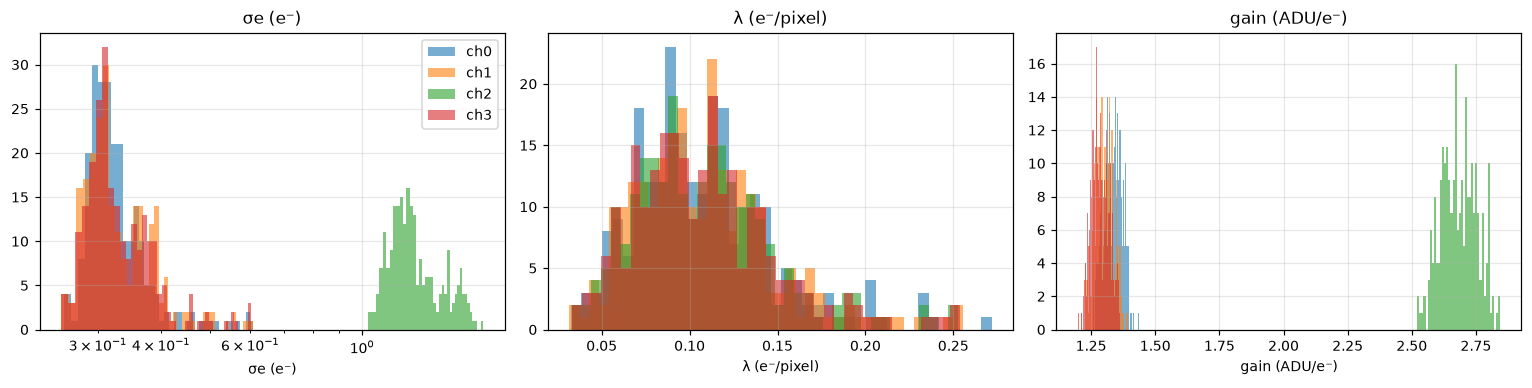

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (col, name) in zip(axes, [("label.sigma_e", "σe (e⁻)"), ("label.lambda_e_per_bin", "λ (e⁻/pixel)"), ("label.gain_adu_per_e", "gain (ADU/e⁻)")]):
    for ch in range(4):
        ax.hist(train_df[train_df.channel == ch][col], 40, alpha=0.6, label=f"ch{ch}")
    ax.set(title=name, xlabel=name)
axes[0].legend(); axes[0].set_xscale("log")
plt.tight_layout(); plt.show()

The labels span factors. The noisy amplifier (ch2) sits apart in σe and gain. For λ, the spread comes from the settings *and* from
the hidden state.

Below, the Allan-deviation curve of the same amplifier in two packets, with the pickup off and on. The floor at large n is the
pickup. The hand-made feature "CDS rms" (the n = 1 value) hardly changes.

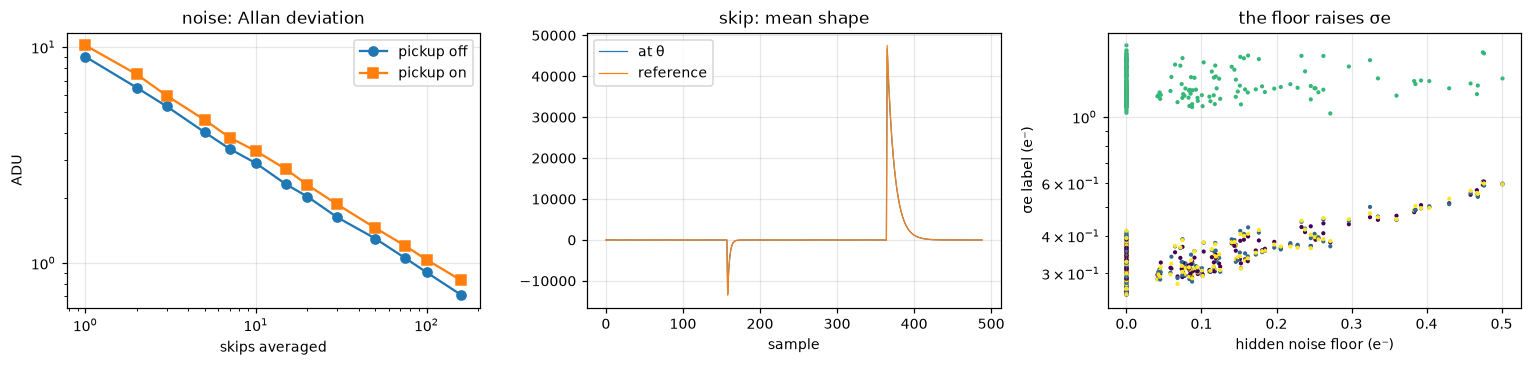

In [4]:
c0 = train_df.channel == 0
on, off = np.flatnonzero(c0 & (train_df["truth.pickup"] == 1))[0], np.flatnonzero(c0 & (train_df["truth.pickup"] == 0))[0]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].loglog(synthetic.ALLAN_N, train_curves["noise: Allan deviation"][off], "o-", label="pickup off")
axes[0].loglog(synthetic.ALLAN_N, train_curves["noise: Allan deviation"][on], "s-", label="pickup on")
axes[0].set(xlabel="skips averaged", ylabel="ADU", title="noise: Allan deviation"); axes[0].legend()
axes[1].plot(train_curves["skip: mean shape"][off], lw=0.8, label="at θ")
axes[1].plot(train_curves["ref: skip: mean shape"][off], lw=0.8, label="reference")
axes[1].set(title="skip: mean shape", xlabel="sample"); axes[1].legend()
axes[2].scatter(train_df["truth.floor"], train_df["label.sigma_e"], s=3, c=train_df["channel"])
axes[2].set(xlabel="hidden noise floor (e⁻)", ylabel="σe label (e⁻)", yscale="log", title="the floor raises σe")
plt.tight_layout(); plt.show()

## 2. Inputs and targets

* `data.make_inputs(df, groups)` builds the input matrix from groups of columns: `theta` (settings), `amp` (which amplifier, one-hot),
  `trace` (features at θ), `ref` (features of the reference traces of the same packet), `diff` (trace − ref).
* `data.curve_tensor(curves, names)` stacks curves as channels for the CNN (spectra and Allan deviations in log).
* `data.make_targets(df)` gives **log σe, log λ, log gain**: logs because all three are positive and span factors, and an error in a log
  is a relative error (0.05 = 5 %).

In [5]:
Y_tr, targets = data.make_targets(train_df)
Y_te, _ = data.make_targets(test_df)
inputs = {
    "theta + amp": ("theta", "amp"),
    "theta + amp + features": ("theta", "amp", "trace", "ref"),
}
X = {name: (data.make_inputs(train_df, g, drop_constant=False)[0], data.make_inputs(test_df, g, drop_constant=False)[0])
     for name, g in inputs.items()}
curve_names = sorted(synthetic.CURVES) + ["ref: " + n for n in sorted(synthetic.CURVES)]
log_names = tuple(n for n in curve_names if "Allan" in n or "spectrum" in n or "variation" in n)
C_tr = data.curve_tensor(train_curves, curve_names, log_names=log_names)
C_te = data.curve_tensor(test_curves, curve_names, log_names=log_names)
for name, (a, b) in X.items():
    print(f"{name:26s} {a.shape[1]:3d} inputs")
print(f"{'curves (CNN)':26s} {C_tr.shape[1]} curves x {C_tr.shape[2]} points")

theta + amp                 14 inputs
theta + amp + features      48 inputs
curves (CNN)               14 curves x 256 points


## 3. The five model types

All have the same interface: `fit(X, Y)` and `predict(X) -> (mean, std)`. Each is trained on the 240-packet scan and scored on the
independent 200-packet scan. Error = root-mean-square of log(prediction/truth), i.e. a relative error.

| Model | Idea |
|---|---|
| Bayesian ridge | weighted sum of the inputs (the yardstick) |
| boosted trees | hundreds of small decision trees, each correcting the previous ones |
| Gaussian process | similarity-weighted average of the training packets; one length scale per input |
| NN ensemble | 5 small neural networks, each predicting a value and its variance |
| 1D CNN | learns its own filters on the curves (here with θ + amplifier added) |

In [6]:
def run(make, Xtr, Xte):
    m = make().fit(Xtr, Y_tr)
    mean, std = m.predict(Xte)
    return m, mean, std, evaluate.scores(Y_te, mean, std, targets)

rows, fitted = [], {}
for name in inputs:
    for key in ["ridge", "gbt", "gp", "mlp"]:
        m, mean, std, sc = run(models.MODELS[key], *X[name])
        fitted[(name, key)] = (m, mean, std)
        rows.append({"inputs": name, "model": models.MODELS[key].name,
                     **{f"{t} error %": 100 * sc[t]["rel_error"] for t in targets},
                     **{f"{t} coverage": sc[t]["coverage"] for t in targets}})
cnn_in_tr = {"curves": C_tr, "scalars": X["theta + amp"][0]}
cnn_in_te = {"curves": C_te, "scalars": X["theta + amp"][1]}
m, mean, std, sc = run(models.CurveCNN, cnn_in_tr, cnn_in_te)
fitted[("curves + theta + amp", "cnn")] = (m, mean, std)
rows.append({"inputs": "curves + theta + amp", "model": models.CurveCNN.name,
             **{f"{t} error %": 100 * sc[t]["rel_error"] for t in targets},
             **{f"{t} coverage": sc[t]["coverage"] for t in targets}})
table = pd.DataFrame(rows)
table.round(2)

,inputs,model,sigma_e error %,lambda error %,gain error %,sigma_e coverage,lambda coverage,gain coverage
0,theta + amp,Bayesian ridge,13.07,20.04,0.90,0.77,0.78,0.74
1,theta + amp,boosted trees,13.07,22.25,1.00,0.41,0.27,0.50
2,theta + amp,Gaussian process,12.15,25.94,0.92,0.72,0.68,0.72
3,theta + amp,neural-net ensemble,12.51,21.42,1.12,0.63,0.63,0.77
4,theta + amp + features,Bayesian ridge,12.50,9.59,0.83,0.80,0.74,0.70
5,theta + amp + features,boosted trees,12.86,11.51,0.92,0.44,0.59,0.60
6,theta + amp + features,Gaussian process,11.61,3.57,0.84,0.77,0.67,0.70
7,theta + amp + features,neural-net ensemble,12.38,4.15,0.92,0.71,0.72,0.75
8,curves + theta + amp,1D CNN on curves,10.86,4.28,0.91,0.66,0.69,0.74


**Reading the table:**

* **θ alone cannot predict λ well**: the hidden state is not in θ. The reference features measure it, and the error drops several-fold.
  This is why every packet takes reference traces.
* **σe is stuck near 12 % for every feature-based model**: the pickup floor is invisible to the hand-made features.
* **The CNN on the curves** does better on σe. With 240 packets it is just beginning to use the floor; see the learning curves in step 6.
* **Gain** is easy for everyone (it is set mostly by the amplifier).

(A single training run; differences of a few percent between models are within run-to-run variation.)

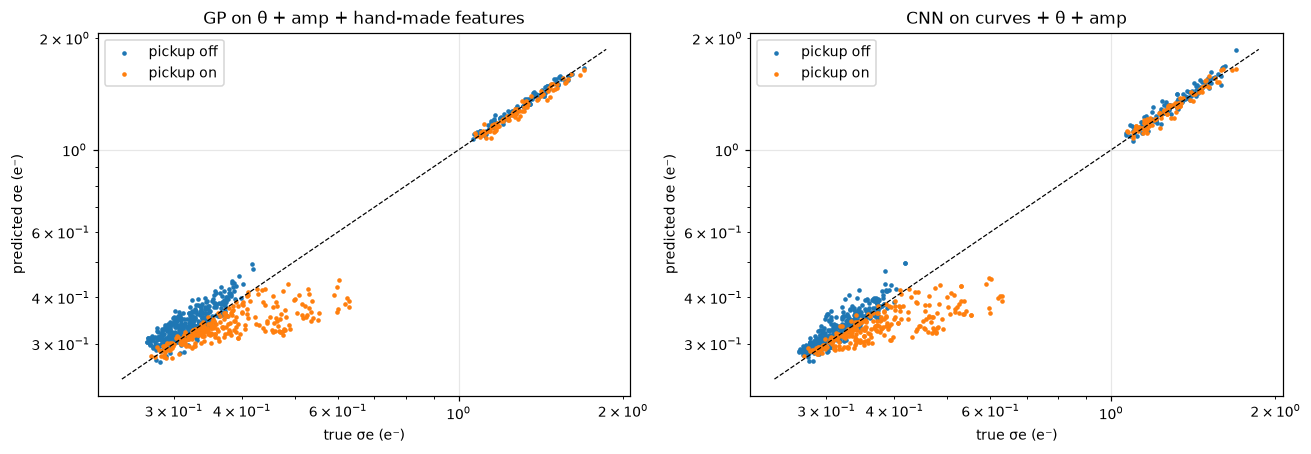

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
pick = test_df["truth.pickup"].to_numpy() == 1
for ax, key, title in zip(axes, [("theta + amp + features", "gp"), ("curves + theta + amp", "cnn")],
                          ["GP on θ + amp + hand-made features", "CNN on curves + θ + amp"]):
    mean = fitted[key][1][:, 0]
    ax.scatter(np.exp(Y_te[~pick, 0]), np.exp(mean[~pick]), s=4, label="pickup off")
    ax.scatter(np.exp(Y_te[pick, 0]), np.exp(mean[pick]), s=4, label="pickup on")
    lim = [np.exp(Y_te[:, 0]).min() * 0.9, np.exp(Y_te[:, 0]).max() * 1.1]
    ax.plot(lim, lim, "k--", lw=0.8)
    ax.set(xscale="log", yscale="log", xlabel="true σe (e⁻)", ylabel="predicted σe (e⁻)", title=title)
    ax.legend()
plt.tight_layout(); plt.show()

With the pickup on, the feature model predicts too low a noise: it cannot see the floor. The CNN starts to separate the two cases.

## 4. Error bars

A model for the optimizer must know when it is unsure. **Coverage** is the fraction of test points whose truth lies within the
predicted mean ± 1 std; for honest Gaussian error bars it is 0.68. Below: the coverage for every model and target, and the error against
the predicted std for the GP (the points should follow the dashed 1σ lines).

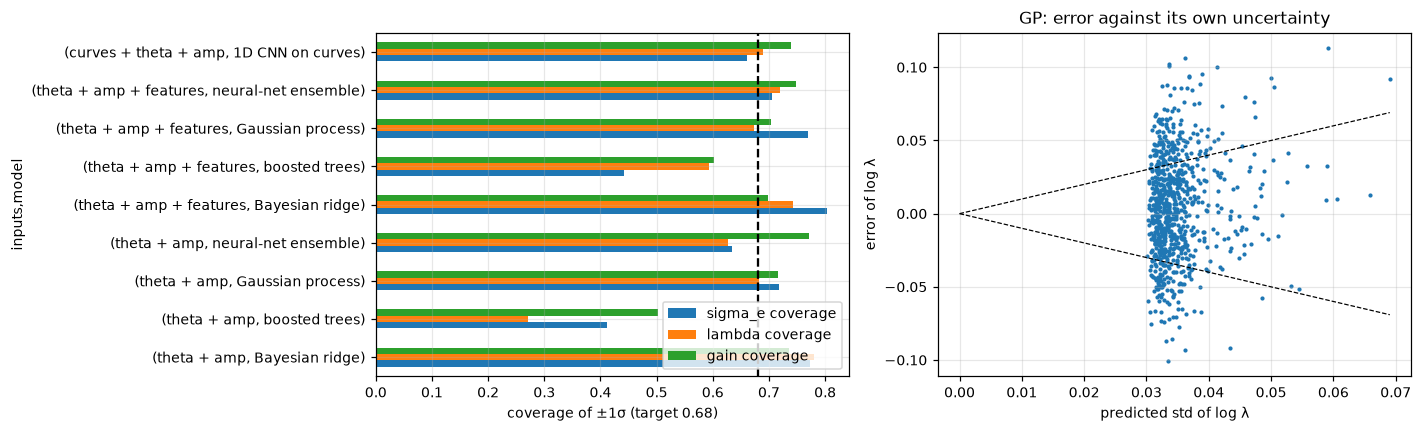

In [8]:
cov = table.set_index(["inputs", "model"])[[f"{t} coverage" for t in targets]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cov.plot.barh(ax=axes[0], legend=True)
axes[0].axvline(0.68, color="k", ls="--"); axes[0].set_xlabel("coverage of ±1σ (target 0.68)")
m, mean, std = fitted[("theta + amp + features", "gp")]
err = mean[:, 1] - Y_te[:, 1]
axes[1].scatter(std[:, 1], err, s=3)
s = np.linspace(0, std[:, 1].max(), 10)
axes[1].plot(s, s, "k--", lw=0.8); axes[1].plot(s, -s, "k--", lw=0.8)
axes[1].set(xlabel="predicted std of log λ", ylabel="error of log λ", title="GP: error against its own uncertainty")
plt.tight_layout(); plt.show()

The GP and the neural-network ensembles are close to 0.68. The boosted trees' quantile error bars are too narrow with this little
data, so they are not used to drive the optimizer.

## 5. What the Gaussian process uses

The GP has one length scale ℓ per input; 1/ℓ is its relevance. An input that does not matter gets a huge ℓ.

In [9]:
m = fitted[("theta + amp + features", "gp")][0]
names = data.make_inputs(train_df, inputs["theta + amp + features"], drop_constant=False)[1]
for t, target in enumerate(targets):
    rel = 1 / m.length_scales(t)
    top = np.argsort(-rel)[:6]
    print(f"log {target:8s}: " + ", ".join(f"{names[i]} ({rel[i]:.2f})" for i in top))

log sigma_e : trace.skip: CDS rms (detrended) (0.36), amp.100_ch2 (0.34), ref.edge: rise time (ns) (0.18), ref.vertical: minimum (0.10), trace.fit: dip recovery time (us) (0.02), trace.skip: dip height (0.01)
log lambda  : ref.skip: baseline at skip 1 (0.14), amp.100_ch2 (0.14), amp.100_ch1 (0.13), theta.V_low (0.08), ref.fit: baseline droop amplitude (0.08), trace.fit: baseline droop amplitude (0.07)
log gain    : amp.100_ch2 (0.41), ref.fit: baseline droop amplitude (0.03), theta.VDD (0.03), ref.noise: within-cycle power 1-3 MHz (0.03), trace.fit: dip recovery time (us) (0.03), theta.VR (0.01)


The choices are the physically right ones:

* the CDS noise per skip for σe;
* the reference baseline (which carries the hidden state) and the V low rails for λ;
* the amplifier for the gain.

## 6. The benchmark: how many packets, features or curves, a new module

These are expensive to recompute (about an hour), so the results of `python -m ml.benchmark` are loaded from `docs/ml_results/`.

### 6a. Number of training packets

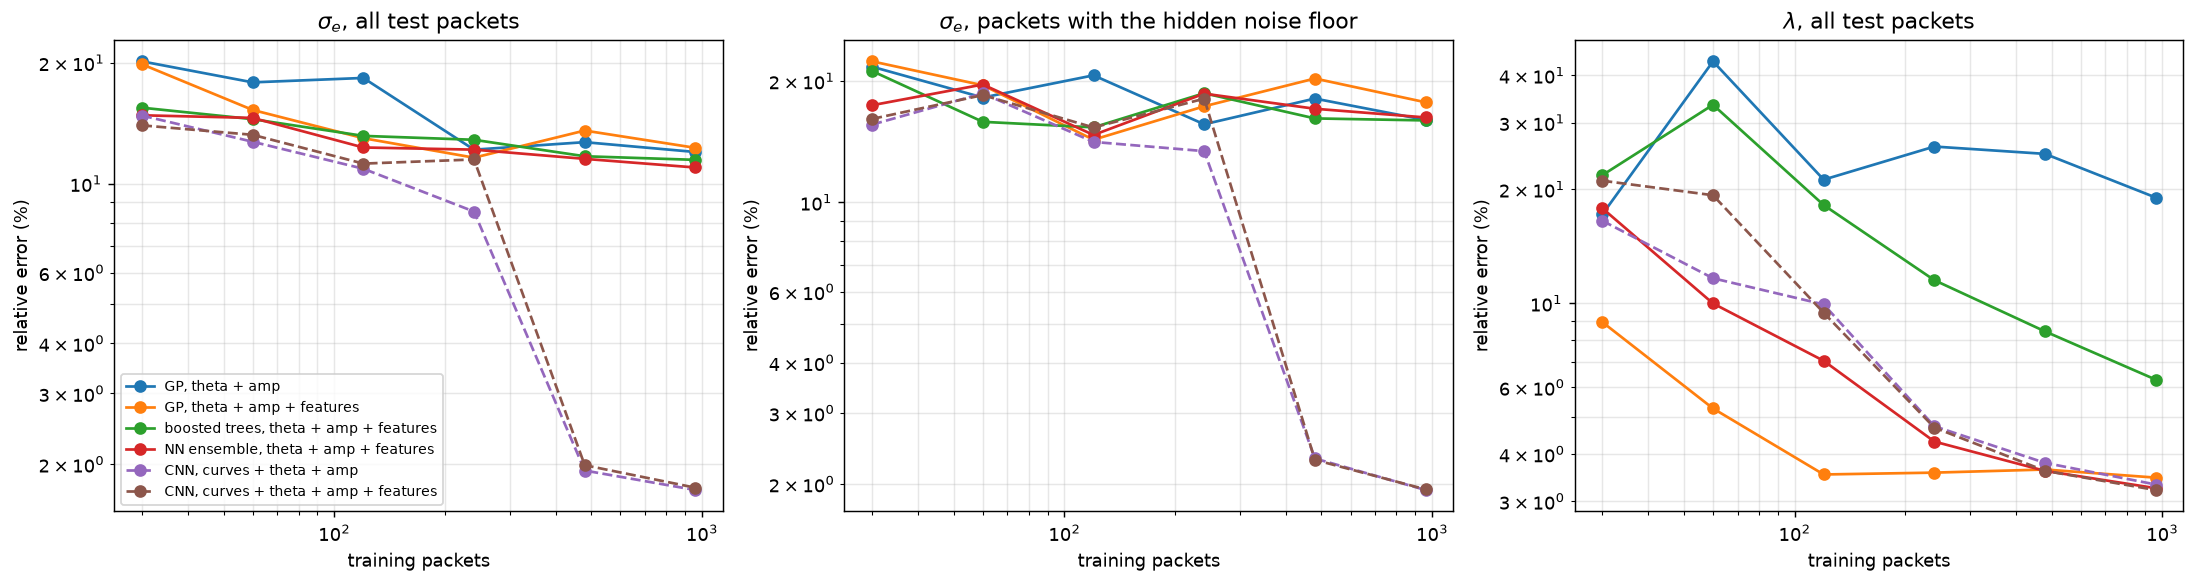

,30,60,120,240,480,960
σe error (%) at n training packets,,,,,,
"GP, theta + amp",20.2,17.9,18.3,12.2,12.7,12.0
"GP, theta + amp + features",19.8,15.3,13.0,11.6,13.6,12.3
"boosted trees, theta + amp + features",15.5,14.5,13.2,12.9,11.7,11.5
"NN ensemble, theta + amp + features",14.8,14.6,12.3,12.2,11.5,11.0
"CNN, curves + theta + amp",14.8,12.7,10.9,8.5,1.9,1.7
"CNN, curves + theta + amp + features",14.0,13.2,11.2,11.5,2.0,1.7


In [10]:
from IPython.display import Image, display
display(Image(filename=str(FIGS / "ml_learning_curves.png"), width=1000))
learning = json.loads((RESULTS / "learning.json").read_text())
pd.DataFrame({label: {int(n): round(100 * r["all"]["sigma_e"]["rel_error"], 1) for n, r in v.items()}
              for label, v in learning.items()}).T.rename_axis("σe error (%) at n training packets")

The feature-based models level off around 11–12 % for σe; the CNN on the curves overtakes them between 240 and 480 packets (it has found
the pickup floor). **Hand-made features win while data are scarce; learned features win with enough data, if the curves hold more than
the features.**

### 6b. Hand-made features, curves, or both?

Every candidate sees the traces at θ **and** the reference traces; only the representation differs. Dotted lines: without θ.

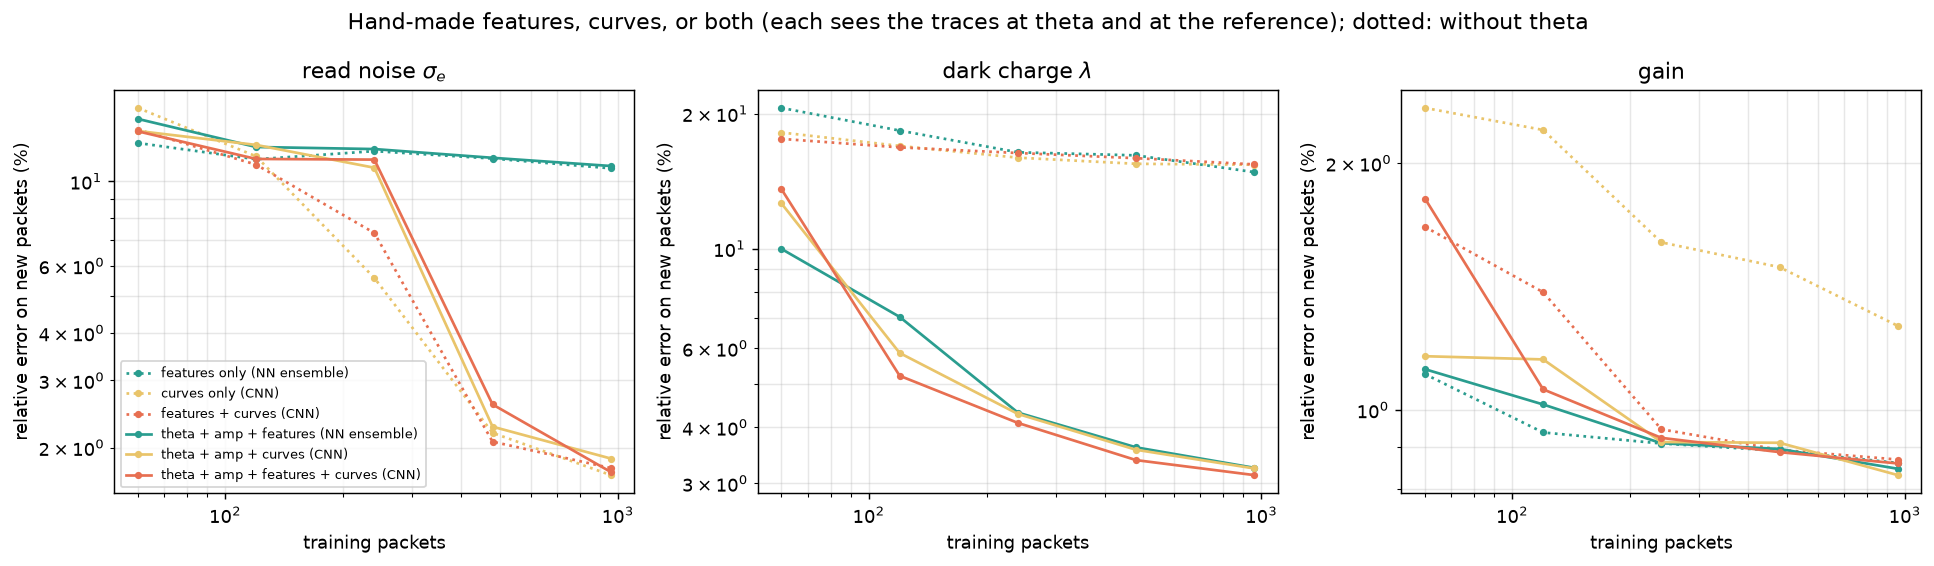

sigma_e                         lambda  \
                                          60    120   240   480   960    60    
curves only (CNN)                        15.6  11.6   5.6   2.2   1.7   18.2   
features + curves (CNN)                  13.7  11.1   7.3   2.1   1.8   17.6   
features only (NN ensemble)              12.6  11.4  12.0  11.5  10.8   20.6   
theta + amp + curves (CNN)               13.6  12.5  10.9   2.3   1.9   12.6   
theta + amp + features (NN ensemble)     14.6  12.3  12.2  11.5  11.0   10.0   
theta + amp + features + curves (CNN)    13.5  11.4  11.4   2.6   1.7   13.6   

                                                              gain            \
                                        120   240   480   960  60   120  240   
curves only (CNN)                      16.9  16.0  15.5  15.4  2.3  2.2  1.6   
features + curves (CNN)                16.8  16.3  15.9  15.4  1.7  1.4  0.9   
features only (NN ensemble)            18.3  16.4  16.1  14.8  1.1  0.9  0.9   
theta + amp + curves (CNN)              5.9   4.3   3.6   3.2  1.2  1.2  0.9   
theta + amp + features (NN ensemble)    7.0   4.3   3.6   3.2  1.1  1.0  0.9   
theta + amp + features + curves (CNN)   5.2   4.1   3.4   3.1  1.8  1.1  0.9   

                                                 
                                       480  960  
curves only (CNN)                      1.5  1.3  
features + curves (CNN)                0.9  0.9  
features only (NN ensemble)            0.9  0.9  
theta + amp + curves (CNN)             0.9  0.8  
theta + amp + features (NN ensemble)   0.9  0.8  
theta + amp + features + curves (CNN)  0.9  0.9

In [11]:
path = RESULTS / "representation.json"
if (FIGS / "ml_representation.png").exists():
    display(Image(filename=str(FIGS / "ml_representation.png"), width=1000))
if path.exists():
    rep = json.loads(path.read_text())
    out = {}
    for label, v in rep.items():
        for n, r in v.items():
            out[(label, int(n))] = {t: round(100 * r["all"][t]["rel_error"], 1) for t in targets}
    display(pd.DataFrame(out).T.unstack(1).round(1))
else:
    print("run: python -m ml.benchmark --only representation")

* **λ needs θ**: without the settings every representation stays around 16 %, because the dark charge depends on rails that the traces
  do not show directly.
* **σe**: with few packets all representations are similar. From a few hundred packets the curves win, and adding the hand-made features
  to the curves neither helps nor hurts much.
* **Practical answer**: give the model **θ + the reference + both representations**. The features carry what we know matters and the
  absolute levels (which the curves remove). The curves carry what we did not think of. With little data the model leans on the
  features; with more data it can use the curves.

### 6c. A module never seen in training

In [12]:
holdout = json.loads((RESULTS / "holdout.json").read_text())
pd.DataFrame({k: {t: round(100 * v[t]["rel_error"], 1) for t in targets} for k, v in holdout.items()}).T

,sigma_e,lambda,gain
k=0 | theta + amp | gbt,67.4,3.3,43.9
k=0 | theta + amp | gp,62.1,19.3,32.9
k=0 | theta + amp + trace + ref | gbt,57.3,50.2,41.3
k=0 | theta + amp + trace + ref | gp,72.0,117.9,35.3
k=5 | theta + amp | gbt,63.1,3.3,35.5
k=5 | theta + amp | gp,15.6,36.6,2.5
k=5 | theta + amp + trace + ref | gbt,19.1,16.6,9.1
k=5 | theta + amp + trace + ref | gp,15.6,37.1,2.5
k=20 | theta + amp | gbt,5.2,3.4,1.8
k=20 | theta + amp | gp,15.1,12.6,1.2


With one module in training, no model predicts a new module well (its gain and noise are outside everything seen). About 5 packets of the
new module fix the gain and about 20 the noise: **start each new module with ~20 packets around its reference**.

## 7. Bayesian optimization: choosing the next settings

The surrogate is a GP of θ → J = log σe + 0.5 log λ (smaller is better). After every packet it is refitted, and the next θ is the allowed
candidate with the largest **expected improvement** (good prediction *or* large uncertainty). Below, a short campaign against random
search (one repeat, 30 packets; the benchmark uses 5 repeats of 60).

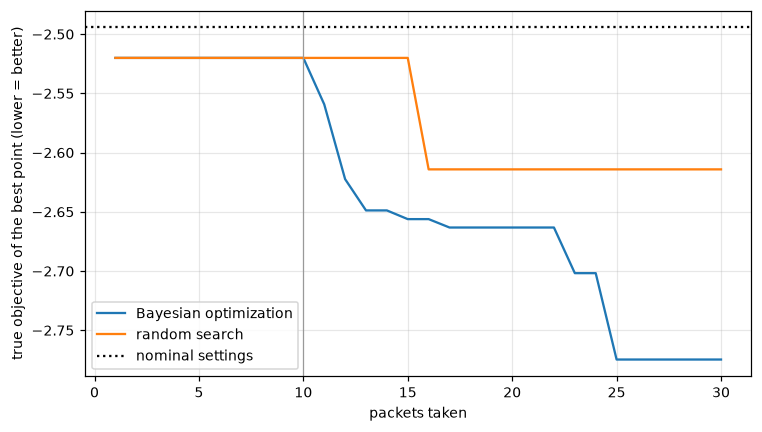

best settings found by BO: {'VDD': -19.9, 'VR': -2.94, 'VSUB': 35.67, 'VDRAIN': -24.33, 'H_low': 6.85, 'V_low': 7.11, 'TG': 7.98, 'RG_high': 7.94, 'SW_low': -5.19, 'delay_H': 1503.59}


In [13]:
rng_noise = np.random.default_rng(7)
measure = lambda theta: synthetic.true_objective(theta) + rng_noise.normal(0, 0.02)
runs = {s: optimize.run_loop(measure, synthetic.LOW, synthetic.HIGH, 10, 30, seed=0, strategy=s, allowed=synthetic.allowed)
        for s in ("bo", "random")}
fig, ax = plt.subplots(figsize=(7, 4))
for s, r in runs.items():
    best = [synthetic.true_objective(r["thetas"][int(np.argmin(r["J"][:k + 1]))]) for k in range(len(r["J"]))]
    ax.plot(range(1, len(best) + 1), best, label={"bo": "Bayesian optimization", "random": "random search"}[s])
ax.axhline(synthetic.true_objective(synthetic.NOMINAL), color="k", ls=":", label="nominal settings")
ax.axvline(10, color="0.6", lw=0.8)
ax.set(xlabel="packets taken", ylabel="true objective of the best point (lower = better)")
ax.legend(); plt.tight_layout(); plt.show()
best_theta = runs["bo"]["thetas"][int(np.argmin(runs["bo"]["J"]))]
print("best settings found by BO:", {n: round(float(v), 2) for n, v in zip(synthetic.NAMES, best_theta)})

## 8. Real data

The same code reads the real output of `process_packet.py`: `dataset.csv` (one row per packet, board and channel) and the curves of
every trace (`.npz` files). Here, the rehearsal packet (fake boards copying old data, so its "labels" are not at varied settings; it only
shows the plumbing).

In [14]:
real = PROJECT / "rehearsal" / "processed" / "dataset.csv"
if real.exists():
    df_real = data.load_dataset(real, only_ok=False)
    Xr, names_r = data.make_inputs(df_real, ("theta", "trace", "ref"), drop_constant=False)
    print(df_real.shape, "rows;", Xr.shape[1], "inputs; e.g.", names_r[:3])
    curves_r = data.curves_from_processed(real.parent, df_real)
    print("curves:", {k: v.shape for k, v in list(curves_r.items())[:4]}, "...")
    Yr, _ = data.make_targets(df_real)
    print("targets (log σe, log λ, log gain) of the first row:", np.round(Yr[0], 3))
else:
    print("no processed packet: run notebooks/process_packet_walkthrough.ipynb first")

no processed packet: run notebooks/process_packet_walkthrough.ipynb first


## What comes next

* **The first real scan** (`configs/scan_recommended.toml`):
  * repeat steps 3–6 on it, with grouped cross-validation and a second night as the test set;
  * read the GP relevances;
  * check the coverage.
* **Models to try next** (the document's section "What the first round taught us"):
  * physics-structured outputs (σe from white noise + floor, λ per row = CIC + DC·t);
  * hierarchical / multi-task GPs across amplifiers and modules (fewer packets for a new module);
  * a CNN encoder with a GP head (deep kernel learning), pre-trained on the unlabeled traces;
  * conformal calibration of every model's error bars;
  * multi-fidelity Bayesian optimization that decides between trace-only and full packets.